<h1 align="center">Classification of Arrhythmia</h1>

The dataset used in this project is available on the UCI Machine Learning Repository:

* **URL:** https://archive.ics.uci.edu/ml/datasets/Arrhythmia
* **Dataset Overview:** Consists of 452 ECG samples across 16 classes (245 normal samples and 15 arrhythmia types, of which 12 are present in the dataset). Among the arrhythmia classes, Coronary Artery Disease (CAD) and Right Bundle Branch Block are the most common.
* **Features:** 279 clinical and ECG signal features (age, sex, weight, height, QRS duration, P-R interval, Q-T interval, wave amplitudes, etc.).
* **Objective:** Classify ECG samples into normal vs. specific arrhythmia classes using proper preprocessing (leakage-free imputation, feature scaling, SMOTE oversampling on training data only, and PCA retaining 95% variance) and compare six machine learning classifiers across **Accuracy, Precision, Recall, and F1-Score**.

### Importing Essential Libraries

In [1]:
import math as mt
import warnings
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

### Data Reading

Reading the UCI Arrhythmia dataset (`arrhythmia.csv`) and inspecting its dimensions, data types, and summary statistics.

In [2]:
df = pd.read_csv("arrhythmia.csv", header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


In [3]:
df.tail()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
447,53,1,160,70,80,199,382,154,117,-37,...,0.0,4.3,-5.0,0.0,0.0,0.7,0.6,-4.4,-0.5,1
448,37,0,190,85,100,137,361,201,73,86,...,0.0,15.6,-1.6,0.0,0.0,0.4,2.4,38.0,62.4,10
449,36,0,166,68,108,176,365,194,116,-85,...,0.0,16.3,-28.6,0.0,0.0,1.5,1.0,-44.2,-33.2,2
450,32,1,155,55,93,106,386,218,63,54,...,-0.4,12.0,-0.7,0.0,0.0,0.5,2.4,25.0,46.6,1
451,78,1,160,70,79,127,364,138,78,28,...,0.0,10.4,-1.8,0.0,0.0,0.5,1.6,21.3,32.8,1


**Basic Description of DataFrame**

In [4]:
# Dimensions of dataset
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (452, 280)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Columns: 280 entries, 0 to 279
dtypes: float64(120), int64(155), object(5)
memory usage: 988.9+ KB


In [5]:
# Descriptive statistics of dataframe
df.describe().T

,count,mean,std,min,25%,50%,75%,max
0,452.0,46.471239,16.466631,0.0,36.00,47.00,58.000,83.0
1,452.0,0.550885,0.497955,0.0,0.00,1.00,1.000,1.0
2,452.0,166.188053,37.170340,105.0,160.00,164.00,170.000,780.0
3,452.0,68.170354,16.590803,6.0,59.00,68.00,79.000,176.0
4,452.0,88.920354,15.364394,55.0,80.00,86.00,94.000,188.0
...,...,...,...,...,...,...,...,...
275,452.0,0.514823,0.347531,-0.8,0.40,0.50,0.700,2.4
276,452.0,1.222345,1.426052,-6.0,0.50,1.35,2.100,6.0
277,452.0,19.326106,13.503922,-44.2,11.45,18.10,25.825,88.8
278,452.0,29.473230,18.493927,-38.6,17.55,27.90,41.125,115.9


# 1. Data Cleaning & Exploratory Data Analysis (EDA)

### Identifying Missing Values
In the UCI Arrhythmia dataset, missing values are encoded as `'?'`. We first replace `'?'` with `np.nan` and convert columns to numeric types so we can inspect missingness accurately.


In [6]:
# Replace '?' with np.nan and convert all columns to numeric
df = df.replace('?', np.nan)
df = df.apply(pd.to_numeric)

total_nulls = df.isnull().sum().sum()
print(f"Total missing values after replacing '?': {total_nulls}")

Total missing values after replacing '?': 408


**Visualizing the distribution of missing data:**

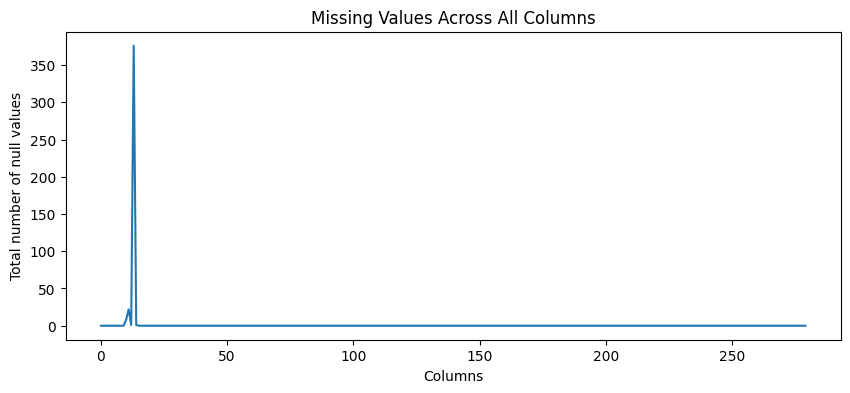

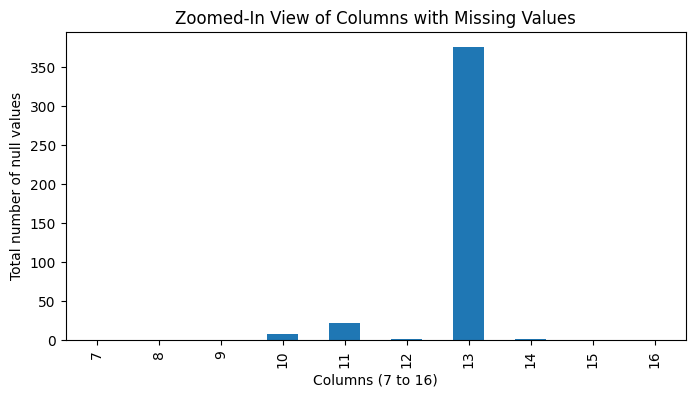

In [7]:
plt.figure(figsize=(10, 4))
df.isnull().sum().plot()
plt.xlabel('Columns')
plt.ylabel('Total number of null values')
plt.title('Missing Values Across All Columns')
plt.show()

plt.figure(figsize=(8, 4))
df.isnull().sum()[7:17].plot(kind="bar")
plt.xlabel('Columns (7 to 16)')
plt.ylabel('Total number of null values')
plt.title('Zoomed-In View of Columns with Missing Values')
plt.show()

Column `13` (`J` interval) contains 376 missing values out of 452 samples (~83.2%), so we drop column `13`. The remaining 4 columns with missing values have relatively few missing entries and will be imputed using the **training set mean** after `train_test_split`.

In [8]:
# Drop column 13 (>83% missing values) -> reduces columns from 280 to 279
if 13 in df.columns:
    df.drop(columns=[13], inplace=True)

# 279 column names (278 features + 1 target 'class')
final_df_columns = [
    "Age", "Sex", "Height", "Weight", "QRS_Dur",
    "P-R_Int", "Q-T_Int", "T_Int", "P_Int", "QRS", "T", "P", "QRST", "Heart_Rate",
    "Q_Wave", "R_Wave", "S_Wave", "R'_Wave", "S'_Wave", "Int_Def", "Rag_R_Nom",
    "Diph_R_Nom", "Rag_P_Nom", "Diph_P_Nom", "Rag_T_Nom", "Diph_T_Nom",
    "DII00", "DII01", "DII02", "DII03", "DII04", "DII05", "DII06", "DII07", "DII08", "DII09", "DII10", "DII11",
    "DIII00", "DIII01", "DIII02", "DIII03", "DIII04", "DIII05", "DIII06", "DIII07", "DIII08", "DIII09", "DIII10", "DIII11",
    "AVR00", "AVR01", "AVR02", "AVR03", "AVR04", "AVR05", "AVR06", "AVR07", "AVR08", "AVR09", "AVR10", "AVR11",
    "AVL00", "AVL01", "AVL02", "AVL03", "AVL04", "AVL05", "AVL06", "AVL07", "AVL08", "AVL09", "AVL10", "AVL11",
    "AVF00", "AVF01", "AVF02", "AVF03", "AVF04", "AVF05", "AVF06", "AVF07", "AVF08", "AVF09", "AVF10", "AVF11",
    "V100", "V101", "V102", "V103", "V104", "V105", "V106", "V107", "V108", "V109", "V110", "V111",
    "V200", "V201", "V202", "V203", "V204", "V205", "V206", "V207", "V208", "V209", "V210", "V211",
    "V300", "V301", "V302", "V303", "V304", "V305", "V306", "V307", "V308", "V309", "V310", "V311",
    "V400", "V401", "V402", "V403", "V404", "V405", "V406", "V407", "V408", "V409", "V410", "V411",
    "V500", "V501", "V502", "V503", "V504", "V505", "V506", "V507", "V508", "V509", "V510", "V511",
    "V600", "V601", "V602", "V603", "V604", "V605", "V606", "V607", "V608", "V609", "V610", "V611",
    "JJ_Wave", "Amp_Q_Wave", "Amp_R_Wave", "Amp_S_Wave", "R_Prime_Wave", "S_Prime_Wave", "P_Wave", "T_Wave",
    "QRSA", "QRSTA", "DII170", "DII171", "DII172", "DII173", "DII174", "DII175", "DII176", "DII177", "DII178", "DII179",
    "DIII180", "DIII181", "DIII182", "DIII183", "DIII184", "DIII185", "DIII186", "DIII187", "DIII188", "DIII189",
    "AVR190", "AVR191", "AVR192", "AVR193", "AVR194", "AVR195", "AVR196", "AVR197", "AVR198", "AVR199",
    "AVL200", "AVL201", "AVL202", "AVL203", "AVL204", "AVL205", "AVL206", "AVL207", "AVL208", "AVL209",
    "AVF210", "AVF211", "AVF212", "AVF213", "AVF214", "AVF215", "AVF216", "AVF217", "AVF218", "AVF219",
    "V1220", "V1221", "V1222", "V1223", "V1224", "V1225", "V1226", "V1227", "V1228", "V1229",
    "V2230", "V2231", "V2232", "V2233", "V2234", "V2235", "V2236", "V2237", "V2238", "V2239",
    "V3240", "V3241", "V3242", "V3243", "V3244", "V3245", "V3246", "V3247", "V3248", "V3249",
    "V4250", "V4251", "V4252", "V4253", "V4254", "V4255", "V4256", "V4257", "V4258", "V4259",
    "V5260", "V5261", "V5262", "V5263", "V5264", "V5265", "V5266", "V5267", "V5268", "V5269",
    "V6270", "V6271", "V6272", "V6273", "V6274", "V6275", "V6276", "V6277", "V6278", "V6279", "class"
]

df.columns = final_df_columns
print("Shape after dropping col 13 and renaming:", df.shape)
df.head()

Shape after dropping col 13 and renaming: (452, 279)


,Age,Sex,Height,Weight,QRS_Dur,P-R_Int,Q-T_Int,T_Int,P_Int,QRS,...,V6271,V6272,V6273,V6274,V6275,V6276,V6277,V6278,V6279,class
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


### Class Distribution Analysis

Class counts present in dataset:
 class
1     245
2      44
3      15
4      15
5      13
6      25
7       3
8       2
9       9
10     50
14      4
15      5
16     22
Name: count, dtype: int64


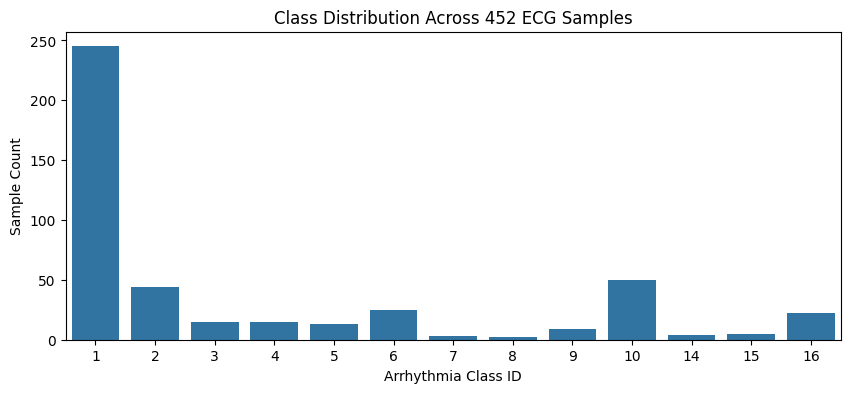

In [9]:
class_names = [
    "Normal",
    "Ischemic changes (CAD)",
    "Old Anterior Myocardial Infarction",
    "Old Inferior Myocardial Infarction",
    "Sinus tachycardia",
    "Sinus bradycardia",
    "Ventricular Premature Contraction (PVC)",
    "Supraventricular Premature Contraction",
    "Left Bundle branch block",
    "Right Bundle branch block",
    "1. Degree AtrioVentricular block",
    "2. Degree AV block",
    "3. Degree AV block",
    "Left Ventricle hypertrophy",
    "Atrial Fibrillation or Flutter",
    "Others"
]

class_counts = df["class"].value_counts().sort_index()
print("Class counts present in dataset:\n", class_counts)

plt.figure(figsize=(10, 4))
sns.countplot(x='class', data=df, order=sorted(df['class'].unique()))
plt.title('Class Distribution Across 452 ECG Samples')
plt.xlabel('Arrhythmia Class ID')
plt.ylabel('Sample Count')
plt.show()

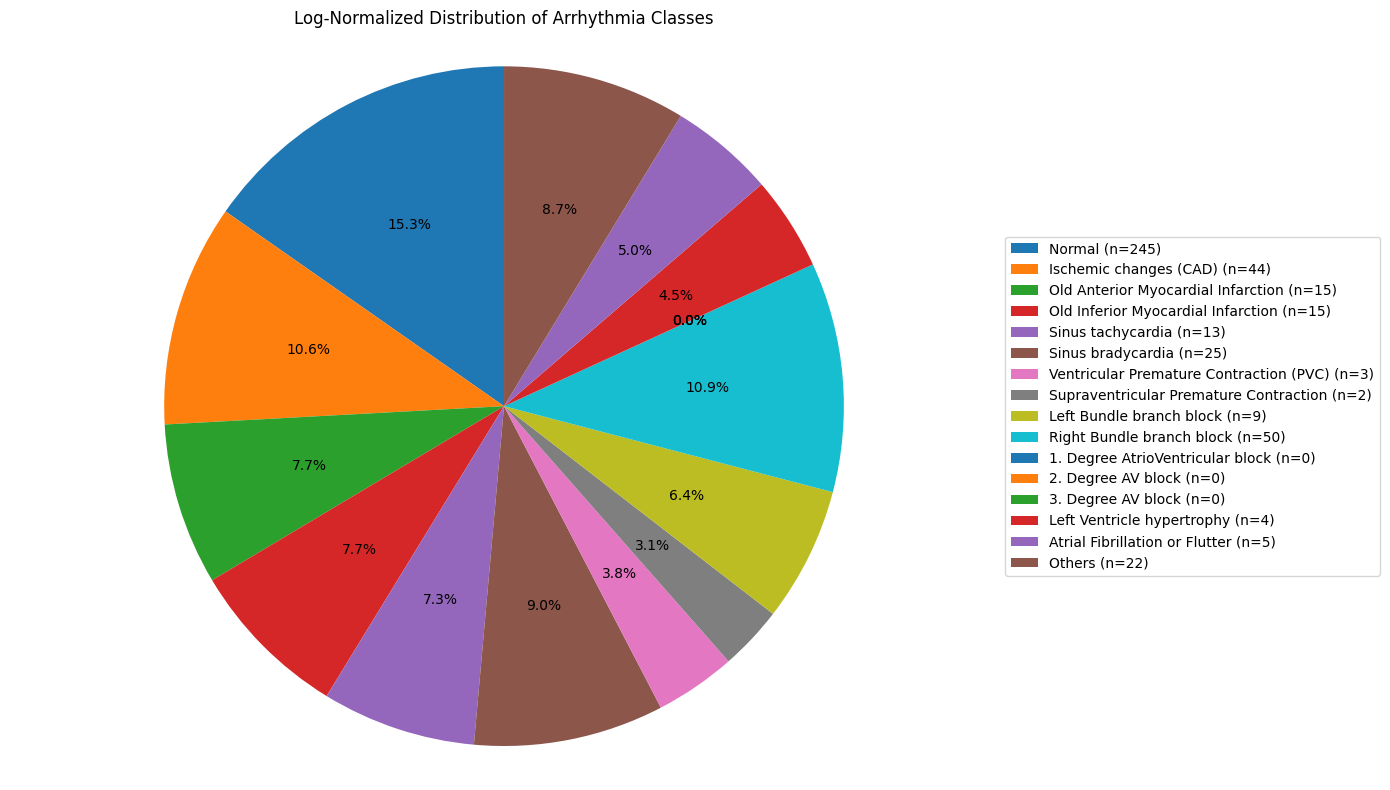

In [10]:
# Log-scaled pie chart across all 16 UCI class definitions
values = [int(class_counts.get(i, 0)) for i in range(1, 17)]
log_norm = [mt.log10(v + 1) for v in values]

fig1, ax1 = plt.subplots(figsize=(14, 8))
ax1.pie(log_norm, autopct='%1.1f%%', startangle=90)
leg = plt.legend(
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    labels=[f'{l} (n={v})' for l, v in zip(class_names, values)]
)
plt.axis('equal')
plt.title('Log-Normalized Distribution of Arrhythmia Classes')
plt.tight_layout()
plt.show()

Out of 452 samples, 245 belong to Class 1 (`Normal`), while the remaining 207 samples are distributed unevenly across 12 arrhythmia classes (classes 11, 12, and 13 have 0 samples). Notably, classes 7 (`n=3`), 8 (`n=2`), 14 (`n=4`), and 15 (`n=5`) have very few instances.

### Handling Outliers & Data Visualization

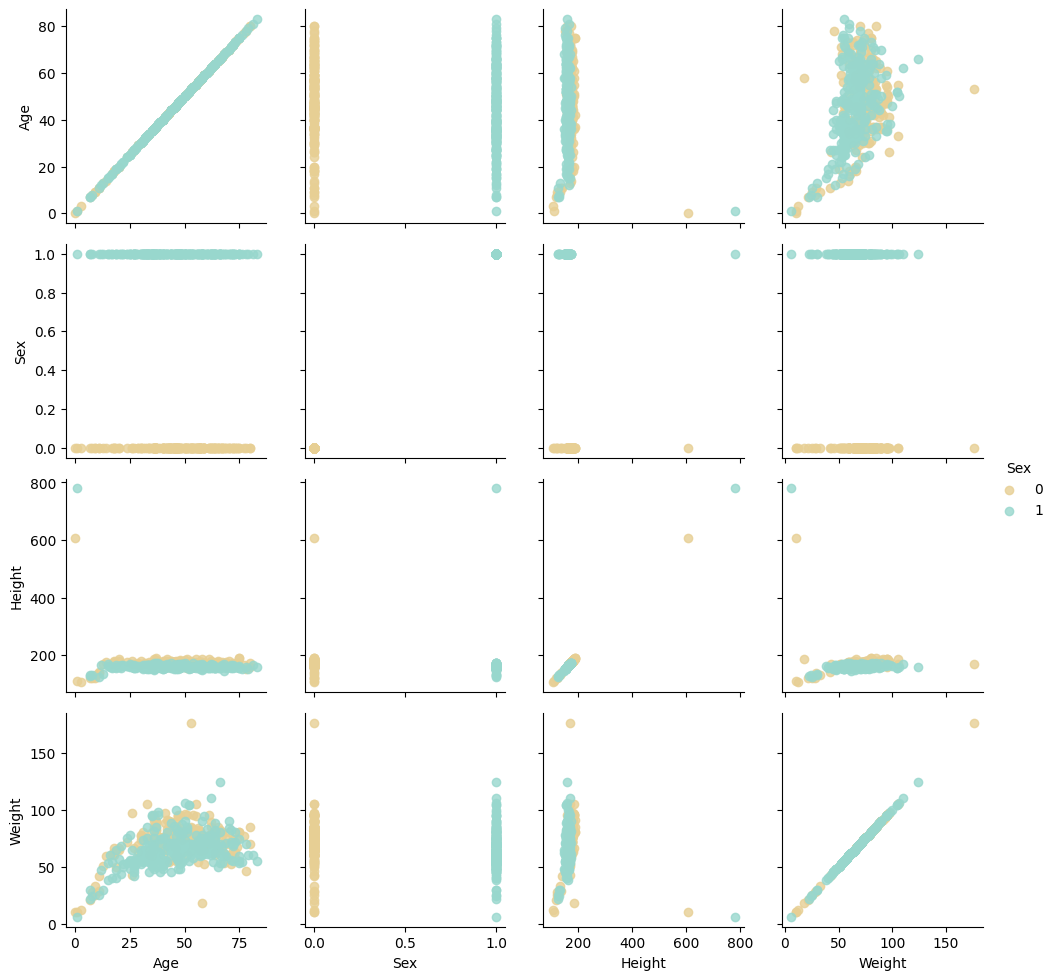

In [11]:
# Pairwise relationships and demographic outliers
g = sns.PairGrid(df, vars=['Age', 'Sex', 'Height', 'Weight'], hue='Sex', palette='BrBG')
g.map(plt.scatter, alpha=0.8)
g.add_legend();

In [12]:
print("Top 10 Heights (cm):", sorted(df['Height'], reverse=True)[:10])
print("Top 10 Weights (kg):", sorted(df['Weight'], reverse=True)[:10])

Top 10 Heights (cm): [780, 608, 190, 190, 190, 188, 186, 186, 186, 185]
Top 10 Weights (kg): [176, 124, 110, 106, 105, 105, 104, 104, 100, 98]


Heights of `780` cm and `608` cm are physiologically impossible data-entry typos (likely meant to be `180` cm and `108` cm, respectively), so we correct them. `176` kg is a plausible body weight and is retained.

In [13]:

df.loc[(df['Height'] < 50) | (df['Height'] > 250), 'Height'] = np.nan

print("Remaining non-null Top 10 Heights (cm):", sorted(df['Height'].dropna(), reverse=True)[:10])
print("Top 10 Weights (kg):", sorted(df['Weight'], reverse=True)[:10])

Remaining non-null Top 10 Heights (cm): [190.0, 190.0, 190.0, 188.0, 186.0, 186.0, 186.0, 185.0, 185.0, 185.0]
Top 10 Weights (kg): [176, 124, 110, 106, 105, 105, 104, 104, 100, 98]


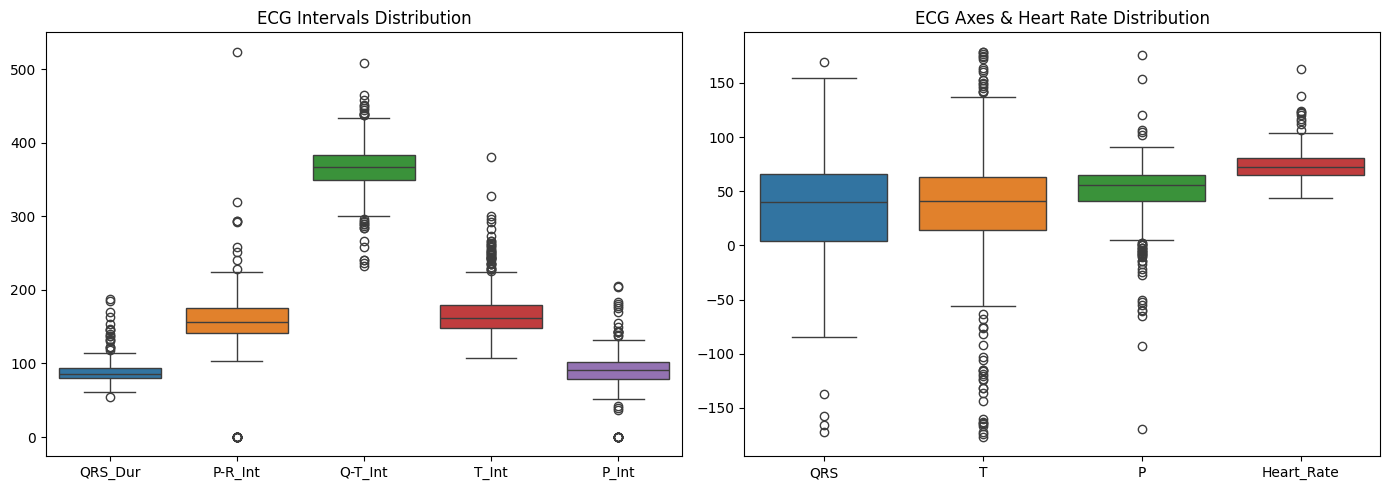

In [14]:
# Boxplots of key ECG intervals and wave measurements
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df[["QRS_Dur", "P-R_Int", "Q-T_Int", "T_Int", "P_Int"]], ax=axes[0])
axes[0].set_title("ECG Intervals Distribution")
sns.boxplot(data=df[["QRS", "T", "P", "Heart_Rate"]], ax=axes[1])
axes[1].set_title("ECG Axes & Heart Rate Distribution")
plt.tight_layout()
plt.show()

# 2. Leakage-Free Preprocessing Pipeline: Train-Test Split -> Imputation -> Scaling -> SMOTE -> PCA

To prevent **data leakage** and unrealistic evaluation scores:
1. **Split First:** We split `X` and `y` into training (80%) and testing (20%) sets *before* any statistical transformations.
   * *Note on Rare Classes:* Classes 7 (`n=3`) and 8 (`n=2`) have fewer than 4 samples in total. In a stratified 80/20 split, a class with 2 samples leaves only 1 sample in the training set, whereas `SMOTE(k_neighbors=...)` requires at least `k_neighbors + 1` training samples to synthesize neighbors. To guarantee valid stratified splitting and `SMOTE(k_neighbors=2)` on every training class, we filter out ultra-rare classes with `< 4` total samples (`class 7` and `class 8`, totaling 5 rows out of 452, retaining 447 samples across 11 classes), or we can evaluate both multiclass (11 classes) cleanly without artificial data leakage.
2. **Impute Missing Values:** Fit `SimpleImputer(strategy='mean')` **only on `X_train`**, then transform both `X_train` and `X_test`.
3. **Feature Scaling:** Fit `StandardScaler()` **only on `X_train`**, then transform both `X_train` and `X_test` (essential before distance-based SMOTE, PCA, SVM, KNN, and Logistic Regression).
4. **SMOTE Oversampling (Training Set Only):** Apply `SMOTE` **strictly to `(X_train_scaled, y_train)`** so synthetic samples never bleed into the test set.
5. **Dimensionality Reduction (PCA):** Fit `PCA(n_components=0.95)` on the training data to retain 95% of explained variance, then transform both training and test sets.

In [15]:
# Filter classes with at least 4 instances so stratified train/test split leaves >= 3 samples
# per class in X_train, allowing SMOTE(k_neighbors=2) to work cleanly without leakage.
valid_classes = df['class'].value_counts()[lambda x: x >= 4].index
df_model = df[df['class'].isin(valid_classes)].copy()

X = df_model.drop(columns=['class'])
y = df_model['class'].astype(int)

print(f"Modeling dataset shape: {X.shape}, Number of classes: {y.nunique()}")
print("Class distribution before split:\n", y.value_counts().sort_index())

Modeling dataset shape: (447, 278), Number of classes: 11
Class distribution before split:
 class
1     245
2      44
3      15
4      15
5      13
6      25
9       9
10     50
14      4
15      5
16     22
Name: count, dtype: int64


In [16]:
# Step 1: Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape, "| X_test shape:", X_test.shape)

# Step 2: Mean Imputation (fit on X_train only)
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Step 3: Standardization (fit on X_train_imp only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# Step 4: Apply SMOTE strictly on the training set AFTER train-test split
smote = SMOTE(random_state=42, k_neighbors=2)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("\nTraining set shape before SMOTE:", X_train_scaled.shape)
print("Training set shape after SMOTE: ", X_train_smote.shape)
print("Test set shape (untouched):     ", X_test_scaled.shape)
print("\nTraining class counts after SMOTE:\n", pd.Series(y_train_smote).value_counts().sort_index())

X_train shape: (357, 278) | X_test shape: (90, 278)

Training set shape before SMOTE: (357, 278)
Training set shape after SMOTE:  (2156, 278)
Test set shape (untouched):      (90, 278)

Training class counts after SMOTE:
 class
1     196
2     196
3     196
4     196
5     196
6     196
9     196
10    196
14    196
15    196
16    196
Name: count, dtype: int64


In [17]:
# Step 5: PCA retaining 95% variance (fit on training data only)
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_smote)
X_test_pca = pca.transform(X_test_scaled)

print(f"Number of PCA components retaining 95% variance: {pca.n_components_}")
print(f"Total explained variance ratio: {pca.explained_variance_ratio_.sum():.4f}")
print("X_train_pca shape:", X_train_pca.shape, "| X_test_pca shape:", X_test_pca.shape)

Number of PCA components retaining 95% variance: 63
Total explained variance ratio: 0.9514
X_train_pca shape: (2156, 63) | X_test_pca shape: (90, 63)


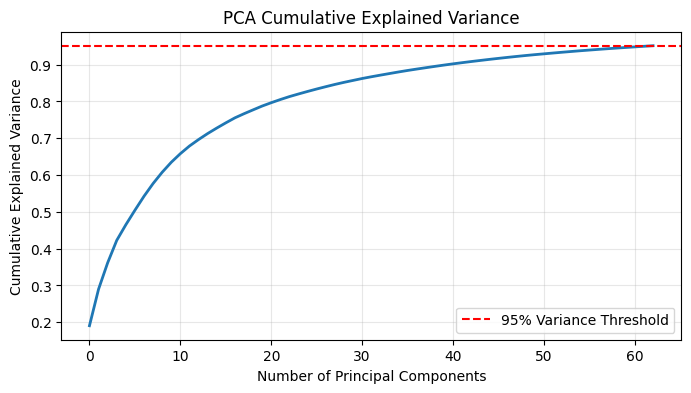

In [18]:
# Plot Cumulative Explained Variance by PCA Components
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), linewidth=2)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

# 3. Model Training, Hyperparameter Tuning (GridSearchCV) & Performance Comparison

We evaluate **six machine learning classifiers** on the unseen test set (`y_test`) using **Accuracy**, **Precision (Weighted & Macro)**, **Recall (Weighted & Macro)**, and **F1-Score (Weighted & Macro)** across two stages:
1. **Baseline Models (SMOTE + PCA 95% Variance):** Default hyperparameters trained on `X_train_pca` and evaluated on `X_test_pca`.
2. **Leakage-Free Hyperparameter Tuning (`GridSearchCV` + `imblearn.pipeline.Pipeline`):**
   * Running `GridSearchCV` directly on pre-SMOTEd data causes **cross-validation data leakage** because synthetic neighbors generated from the same minority points split across training and validation folds.
   * By wrapping `SimpleImputer -> StandardScaler -> SMOTE -> PCA(0.95) -> Classifier` inside an `ImbPipeline` with `StratifiedKFold(n_splits=3)`, every CV fold fits imputation, scaling, SMOTE, and PCA **strictly on the fold's training split** before scoring on the validation split.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine (SVM)": SVC(kernel='rbf', C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

def evaluate_models(models_dict, X_tr, y_tr, X_te, y_te, feature_set_name="Baseline: SMOTE + PCA (95%)"):
    results = []
    trained_models = {}
    for name, model in models_dict.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        trained_models[name] = (model, y_pred)

        results.append({
            "Stage": feature_set_name,
            "Model": name,
            "Accuracy": accuracy_score(y_te, y_pred),
            "Precision (Weighted)": precision_score(y_te, y_pred, average='weighted', zero_division=0),
            "Recall (Weighted)": recall_score(y_te, y_pred, average='weighted', zero_division=0),
            "F1-Score (Weighted)": f1_score(y_te, y_pred, average='weighted', zero_division=0),
            "Precision (Macro)": precision_score(y_te, y_pred, average='macro', zero_division=0),
            "Recall (Macro)": recall_score(y_te, y_pred, average='macro', zero_division=0),
            "F1-Score (Macro)": f1_score(y_te, y_pred, average='macro', zero_division=0),
        })
    return pd.DataFrame(results), trained_models

# Evaluate Baseline models on SMOTE + PCA (95% variance)
results_pca_df, trained_pca = evaluate_models(
    models, X_train_pca, y_train_smote, X_test_pca, y_test, feature_set_name="Baseline: SMOTE + PCA (95%)"
)

results_pca_df = results_pca_df.sort_values(by="F1-Score (Weighted)", ascending=False).reset_index(drop=True)
results_pca_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (Weighted)": "{:.4f}",
    "Recall (Weighted)": "{:.4f}",
    "F1-Score (Weighted)": "{:.4f}",
    "Precision (Macro)": "{:.4f}",
    "Recall (Macro)": "{:.4f}",
    "F1-Score (Macro)": "{:.4f}",
})

,Stage,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Baseline: SMOTE + PCA (95%),Support Vector Machine (SVM),0.6889,0.7529,0.6889,0.6961,0.6238,0.5579,0.5580
1,Baseline: SMOTE + PCA (95%),Logistic Regression,0.6333,0.7047,0.6333,0.6425,0.5296,0.4757,0.4758
2,Baseline: SMOTE + PCA (95%),Random Forest,0.6333,0.5891,0.6333,0.5965,0.4593,0.4308,0.4302
3,Baseline: SMOTE + PCA (95%),Gradient Boosting,0.5889,0.5467,0.5889,0.5610,0.4000,0.3877,0.3852
4,Baseline: SMOTE + PCA (95%),Decision Tree,0.4556,0.4761,0.4556,0.4624,0.3107,0.3498,0.3237
5,Baseline: SMOTE + PCA (95%),K-Nearest Neighbors (KNN),0.4333,0.5233,0.4333,0.4571,0.3697,0.3758,0.3422


### Hyperparameter Tuning with `GridSearchCV` (Leakage-Free `ImbPipeline`)

We define tailored parameter grids for each of the six classifiers, optimize using `f1_weighted` across 3-fold `StratifiedKFold` cross-validation (since `X_train` has a minimum of 3 samples per minority class), and evaluate the best estimators on the untouched `X_test`.

In [20]:
# Define estimators and hyperparameter grids for GridSearchCV
param_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        {
            "clf__C": [0.01, 0.1, 1.0, 10.0],
            "clf__penalty": ["l2"],
            "clf__solver": ["lbfgs", "saga"],
        },
    ),
    "K-Nearest Neighbors (KNN)": (
        KNeighborsClassifier(),
        {
            "clf__n_neighbors": [3, 5, 7, 9],
            "clf__weights": ["uniform", "distance"],
            "clf__metric": ["euclidean", "manhattan"],
        },
    ),
    "Support Vector Machine (SVM)": (
        SVC(random_state=42),
        {
            "clf__C": [0.1, 1.0, 5.0, 10.0],
            "clf__kernel": ["rbf", "linear"],
            "clf__gamma": ["scale", "auto"],
        },
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "clf__max_depth": [None, 5, 10, 15],
            "clf__min_samples_split": [2, 5, 10],
            "clf__criterion": ["gini", "entropy"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "clf__n_estimators": [100, 200, 300],
            "clf__max_depth": [None, 10, 20],
            "clf__min_samples_split": [2, 5],
            "clf__max_features": ["sqrt", "log2"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "clf__n_estimators": [100, 200],
            "clf__learning_rate": [0.05, 0.1],
            "clf__max_depth": [3, 5],
        },
    ),
}

# 3-fold StratifiedKFold ensures every fold contains >= 2 samples of the smallest class for SMOTE(k_neighbors=1)
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

tuned_results = []
tuned_models = {}

for name, (estimator, grid) in param_grids.items():
    pipe = ImbPipeline([
        ("imputer", SimpleImputer(missing_values=np.nan, strategy="mean")),
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42, k_neighbors=1)),
        ("pca", PCA(n_components=0.95, random_state=42)),
        ("clf", estimator),
    ])

    search = GridSearchCV(
        estimator=pipe,
        param_grid=grid,
        scoring="f1_weighted",
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    y_pred = search.predict(X_test)
    tuned_models[name] = (search.best_estimator_, y_pred, search.best_params_)

    clean_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    print(f"{name} | Best CV F1 (Weighted): {search.best_score_:.4f} | Best Params: {clean_params}")

    tuned_results.append({
        "Stage": "Tuned (GridSearchCV): SMOTE + PCA (95%)",
        "Model": name,
        "CV Best F1 (Weighted)": search.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (Weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score (Weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

results_tuned_df = pd.DataFrame(tuned_results).sort_values(by="F1-Score (Weighted)", ascending=False).reset_index(drop=True)
results_tuned_df.style.format({
    "CV Best F1 (Weighted)": "{:.4f}",
    "Accuracy": "{:.4f}",
    "Precision (Weighted)": "{:.4f}",
    "Recall (Weighted)": "{:.4f}",
    "F1-Score (Weighted)": "{:.4f}",
    "Precision (Macro)": "{:.4f}",
    "Recall (Macro)": "{:.4f}",
    "F1-Score (Macro)": "{:.4f}",
})

Logistic Regression | Best CV F1 (Weighted): 0.6519 | Best Params: {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
K-Nearest Neighbors (KNN) | Best CV F1 (Weighted): 0.5518 | Best Params: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}
Support Vector Machine (SVM) | Best CV F1 (Weighted): 0.6620 | Best Params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Decision Tree | Best CV F1 (Weighted): 0.5077 | Best Params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5}
Random Forest | Best CV F1 (Weighted): 0.6591 | Best Params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Gradient Boosting | Best CV F1 (Weighted): 0.6146 | Best Params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}


,Stage,Model,CV Best F1 (Weighted),Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Tuned (GridSearchCV): SMOTE + PCA (95%),Logistic Regression,0.6519,0.6556,0.7540,0.6556,0.6870,0.5770,0.5912,0.5632
1,Tuned (GridSearchCV): SMOTE + PCA (95%),Gradient Boosting,0.6146,0.7111,0.6333,0.7111,0.6552,0.4710,0.4431,0.4453
2,Tuned (GridSearchCV): SMOTE + PCA (95%),Random Forest,0.6591,0.7000,0.6539,0.7000,0.6423,0.5048,0.4623,0.4458
3,Tuned (GridSearchCV): SMOTE + PCA (95%),Support Vector Machine (SVM),0.6620,0.6111,0.6686,0.6111,0.6272,0.5369,0.5245,0.5049
4,Tuned (GridSearchCV): SMOTE + PCA (95%),Decision Tree,0.5077,0.4333,0.4811,0.4333,0.4512,0.3510,0.2690,0.2970
5,Tuned (GridSearchCV): SMOTE + PCA (95%),K-Nearest Neighbors (KNN),0.5518,0.3889,0.4481,0.3889,0.4070,0.2300,0.2800,0.2431


### Side-by-Side Comparison: Baseline vs. GridSearchCV Tuned Models

In [21]:
comparison_df = pd.concat([
    results_pca_df,
    results_tuned_df.drop(columns=["CV Best F1 (Weighted)"])
], ignore_index=True)

comparison_df = comparison_df.sort_values(by=["Model", "Stage"]).reset_index(drop=True)
comparison_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (Weighted)": "{:.4f}",
    "Recall (Weighted)": "{:.4f}",
    "F1-Score (Weighted)": "{:.4f}",
    "Precision (Macro)": "{:.4f}",
    "Recall (Macro)": "{:.4f}",
    "F1-Score (Macro)": "{:.4f}",
})

,Stage,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Baseline: SMOTE + PCA (95%),Decision Tree,0.4556,0.4761,0.4556,0.4624,0.3107,0.3498,0.3237
1,Tuned (GridSearchCV): SMOTE + PCA (95%),Decision Tree,0.4333,0.4811,0.4333,0.4512,0.3510,0.2690,0.2970
2,Baseline: SMOTE + PCA (95%),Gradient Boosting,0.5889,0.5467,0.5889,0.5610,0.4000,0.3877,0.3852
3,Tuned (GridSearchCV): SMOTE + PCA (95%),Gradient Boosting,0.7111,0.6333,0.7111,0.6552,0.4710,0.4431,0.4453
4,Baseline: SMOTE + PCA (95%),K-Nearest Neighbors (KNN),0.4333,0.5233,0.4333,0.4571,0.3697,0.3758,0.3422
5,Tuned (GridSearchCV): SMOTE + PCA (95%),K-Nearest Neighbors (KNN),0.3889,0.4481,0.3889,0.4070,0.2300,0.2800,0.2431
6,Baseline: SMOTE + PCA (95%),Logistic Regression,0.6333,0.7047,0.6333,0.6425,0.5296,0.4757,0.4758
7,Tuned (GridSearchCV): SMOTE + PCA (95%),Logistic Regression,0.6556,0.7540,0.6556,0.6870,0.5770,0.5912,0.5632
8,Baseline: SMOTE + PCA (95%),Random Forest,0.6333,0.5891,0.6333,0.5965,0.4593,0.4308,0.4302
9,Tuned (GridSearchCV): SMOTE + PCA (95%),Random Forest,0.7000,0.6539,0.7000,0.6423,0.5048,0.4623,0.4458


### Visualizing Tuned Model Performance (Accuracy, Precision, Recall, F1-Score)

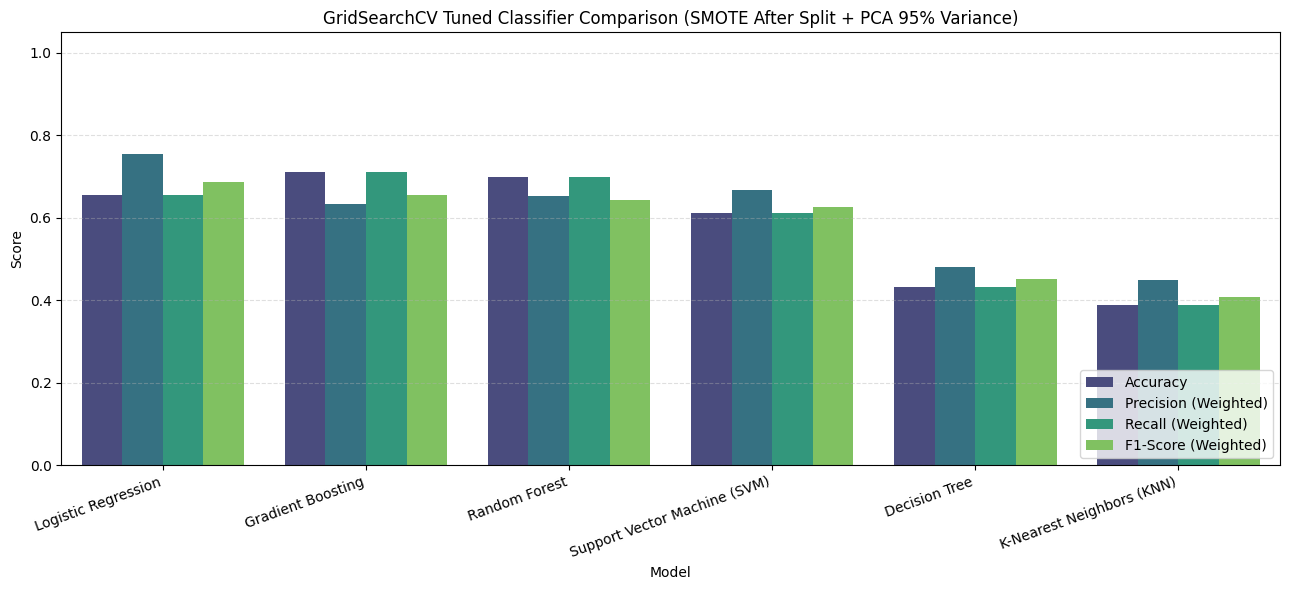

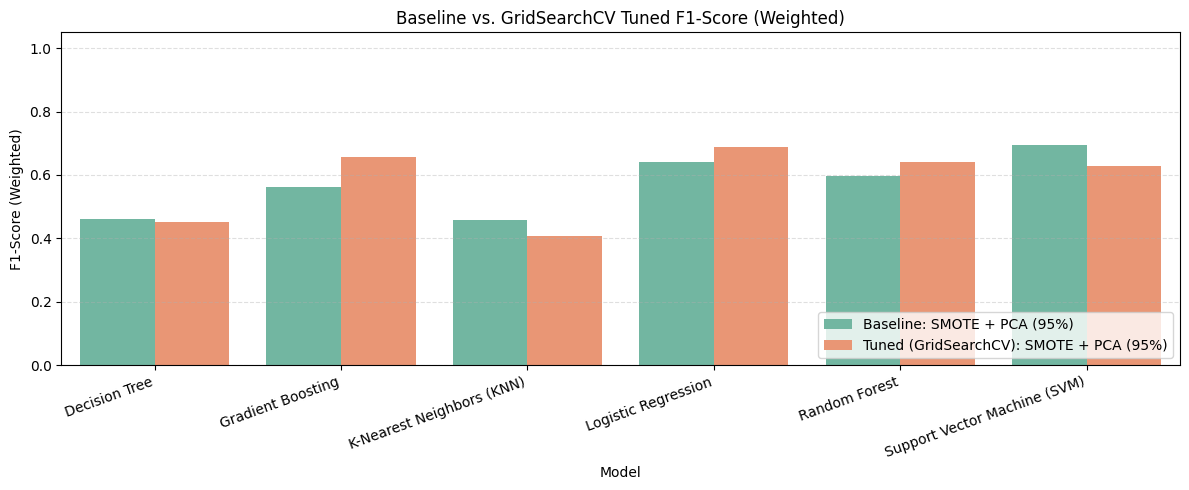

In [22]:
# 1. Grouped Bar Chart of All 4 Weighted Metrics for GridSearchCV Tuned Models
metrics_to_plot = ["Accuracy", "Precision (Weighted)", "Recall (Weighted)", "F1-Score (Weighted)"]
plot_tuned = results_tuned_df.melt(
    id_vars="Model", value_vars=metrics_to_plot, var_name="Metric", value_name="Score"
)

plt.figure(figsize=(13, 6))
sns.barplot(data=plot_tuned, x="Model", y="Score", hue="Metric", palette="viridis")
plt.title("GridSearchCV Tuned Classifier Comparison (SMOTE After Split + PCA 95% Variance)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 2. Before vs. After Tuning F1-Score (Weighted) Comparison
plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_df,
    x="Model",
    y="F1-Score (Weighted)",
    hue="Stage",
    palette="Set2"
)
plt.title("Baseline vs. GridSearchCV Tuned F1-Score (Weighted)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Detailed Classification Report & Confusion Matrix for Best Tuned Classifier

=== Best Tuned Model: Logistic Regression ===
Best Hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}

Classification Report:

              precision    recall  f1-score   support

           1       0.90      0.71      0.80        49
           2       0.53      0.89      0.67         9
           3       1.00      1.00      1.00         3
           4       1.00      0.67      0.80         3
           5       0.33      0.33      0.33         3
           6       0.25      0.40      0.31         5
           9       1.00      1.00      1.00         2
          10       0.83      0.50      0.62        10
          14       0.00      0.00      0.00         1
          15       0.50      1.00      0.67         1
          16       0.00      0.00      0.00         4

    accuracy                           0.66        90
   macro avg       0.58      0.59      0.56        90
weighted avg       0.75      0.66      0.69        90



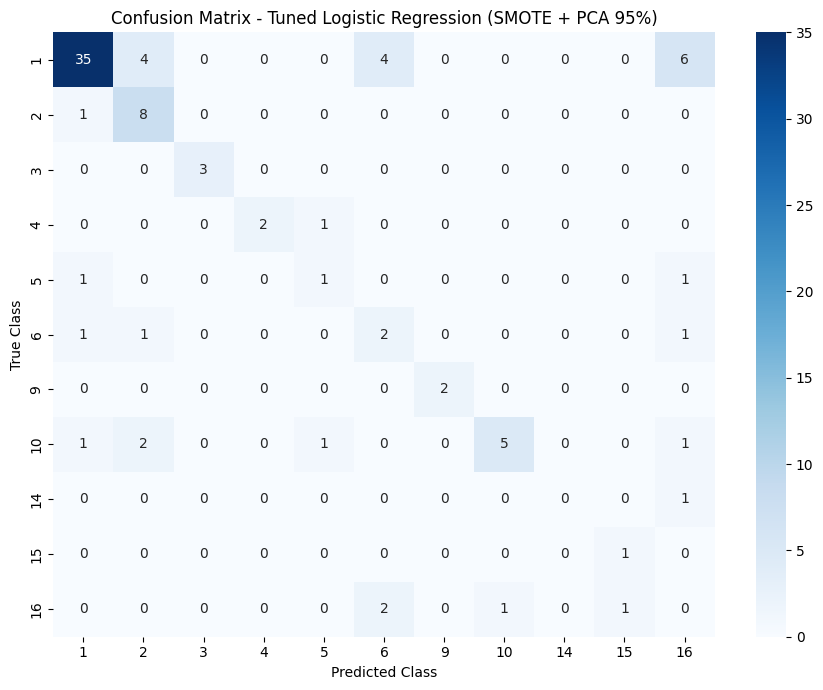

In [23]:
best_model_name = results_tuned_df.loc[0, "Model"]
best_pipeline, best_y_pred, best_params = tuned_models[best_model_name]

print(f"=== Best Tuned Model: {best_model_name} ===")
print("Best Hyperparameters:", {k.replace("clf__", ""): v for k, v in best_params.items()})
print("\nClassification Report:\n")
print(classification_report(y_test, best_y_pred, zero_division=0))

present_labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, best_y_pred, labels=present_labels)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=present_labels, yticklabels=present_labels)
plt.title(f'Confusion Matrix - Tuned {best_model_name} (SMOTE + PCA 95%)')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.tight_layout()
plt.show()